## Praktikum Reinforcement Learning
* Nama : Muhammad Azka Ananta Khairon
* NRP : 5054251004
* link yt : https://youtu.be/ruyeDn4ggf8

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

class ZombieCheckpointEnv:
    """
    Custom Reinforcement Learning Environment: Quarantine Checkpoint
    State Space:
        0: Luka          -> 0: Bersih, 1: Goresan, 2: Gigitan
        1: Pendarahan    -> 0: Tidak Ada, 1: Mimisan, 2: Mulut Berdarah
        2: Warna Kulit   -> 0: Normal, 1: Pucat, 2: Kehijauan
        3: Warna Mata    -> 0: Jernih, 1: Merah, 2: Keruh/Putih
        4: Perilaku      -> 0: Tenang, 1: Gelisah, 2: Agresif
        5: Suhu Tubuh    -> 0: Unknown (Locked), 1: Normal, 2: Demam Tinggi
        6: Pulse (Nadi)  -> 0: Unknown (Locked), 1: Normal, 2: Pulse Tinggi
        7: Tes Darah     -> 0: Unknown (Locked), 1: Negatif (Aman), 2: Positif (Infeksi)
        8: Slot Karantina-> 0: Penuh, 1: Tersedia

    Action Space:
        0: Approve (Izinkan Masuk)
        1: Deny (Tolak / Eliminasi)
        2: Quarantine (Kirim ke Ruang Isolasi)
        3: Check_Vitals (Cek Suhu & Pulse -> Unlock state 5 & 6)
        4: Blood_Test (Tes Darah -> Unlock state 7)
    """

    def __init__(self, max_visitors=50, max_quarantine_slots=3, outbreak_penalty=-100):
        self.max_visitors = max_visitors
        self.max_quarantine_slots = max_quarantine_slots
        self.outbreak_penalty = outbreak_penalty

        self.state_dims = (3, 3, 3, 3, 3, 3, 3, 3, 2)
        self.n_actions = 5
        self.action_names = ["Approve", "Deny", "Quarantine", "Check_Vitals", "Blood_Test"]

        self.reset()

    def _generate_visitor(self):
        """
        Membangkitkan profil pengunjung dengan status tersembunyi (latent_status):
        0: Sehat (~45%), 1: Sakit Biasa (~25%), 2: Terinfeksi Patogen (~30%)
        """
        latent_status = np.random.choice([0, 1, 2], p=[0.45, 0.25, 0.30])

        if latent_status == 0:  # SEHAT
            luka = np.random.choice([0, 1], p=[0.85, 0.15])
            darah = np.random.choice([0, 1], p=[0.90, 0.10])
            kulit = np.random.choice([0, 1], p=[0.90, 0.10])
            mata = np.random.choice([0, 1], p=[0.92, 0.08])
            perilaku = np.random.choice([0, 1], p=[0.85, 0.15])
            true_suhu = 1
            true_pulse = 2 if (perilaku == 1 and np.random.rand() < 0.4) else 1
            true_blood = 1

        elif latent_status == 1:  # SAKIT BIASA (Non-Infeksi)
            luka = np.random.choice([0, 1], p=[0.75, 0.25])
            darah = np.random.choice([0, 1], p=[0.55, 0.45])
            kulit = np.random.choice([0, 1], p=[0.35, 0.65])
            mata = np.random.choice([0, 1], p=[0.40, 0.60])
            perilaku = np.random.choice([0, 1], p=[0.40, 0.60])
            true_suhu = np.random.choice([1, 2], p=[0.30, 0.70])
            true_pulse = np.random.choice([1, 2], p=[0.35, 0.65])
            true_blood = 1

        else:  # TERINFKSI PATOGEN (Zombie)
            is_severe = np.random.rand() < 0.55  # 55% gejala jelas, 45% masa inkubasi (mirip sakit biasa)
            if is_severe:
                luka = np.random.choice([0, 1, 2], p=[0.10, 0.30, 0.60])
                darah = np.random.choice([0, 1, 2], p=[0.10, 0.35, 0.55])
                kulit = np.random.choice([1, 2], p=[0.35, 0.65])
                mata = np.random.choice([1, 2], p=[0.35, 0.65])
                perilaku = np.random.choice([1, 2], p=[0.35, 0.65])
            else:
                luka = np.random.choice([0, 1], p=[0.45, 0.55])
                darah = np.random.choice([0, 1], p=[0.45, 0.55])
                kulit = np.random.choice([0, 1], p=[0.30, 0.70])
                mata = np.random.choice([0, 1], p=[0.30, 0.70])
                perilaku = np.random.choice([0, 1], p=[0.35, 0.65])

            true_suhu = 2
            true_pulse = 2
            true_blood = 2

        self.current_visitor = {
            "latent_status": latent_status,
            "visual": [luka, darah, kulit, mata, perilaku],
            "true_suhu": true_suhu,
            "true_pulse": true_pulse,
            "true_blood": true_blood,
            "vitals_unlocked": False,
            "blood_unlocked": False,
        }

    def _get_state(self):
        v = self.current_visitor
        suhu_obs = v["true_suhu"] if v["vitals_unlocked"] else 0
        pulse_obs = v["true_pulse"] if v["vitals_unlocked"] else 0
        blood_obs = v["true_blood"] if v["blood_unlocked"] else 0
        slot_avail = 1 if len(self.quarantine_timers) < self.max_quarantine_slots else 0

        return tuple(v["visual"] + [suhu_obs, pulse_obs, blood_obs, slot_avail])

    def reset(self):
        self.visitors_processed = 0
        self.quarantine_timers = []
        self.stats = {
            "saved_healthy": 0,
            "blocked_infected": 0,
            "outbreaks": 0,
            "false_rejections": 0,
            "quarantined": 0,
            "vitals_checks": 0,
            "blood_tests": 0,
        }
        self._generate_visitor()
        return self._get_state()

    def _advance_next_visitor(self):
        self.quarantine_timers = [t - 1 for t in self.quarantine_timers if t - 1 > 0]
        self.visitors_processed += 1

        if self.visitors_processed >= self.max_visitors:
            return True
        self._generate_visitor()
        return False

    def step(self, action):
        v = self.current_visitor
        status = v["latent_status"]
        done = False
        reward = 0

        # --- AKSI INVESTIGASI (Tidak mengganti pengunjung) ---
        if action == 3:  # Check_Vitals
            if not v["vitals_unlocked"]:
                v["vitals_unlocked"] = True
                reward = -1
                self.stats["vitals_checks"] += 1
            else:
                reward = -3

        elif action == 4:  # Blood_Test
            if not v["blood_unlocked"]:
                v["blood_unlocked"] = True
                reward = -3
                self.stats["blood_tests"] += 1
            else:
                reward = -5

        # --- AKSI KEPUTUSAN FINAL (Mengganti ke pengunjung berikutnya) ---
        elif action == 0:  # Approve
            if status == 0:
                reward = 10
                self.stats["saved_healthy"] += 1
            elif status == 1:
                reward = 5
                self.stats["saved_healthy"] += 1
            else:
                reward = self.outbreak_penalty
                self.stats["outbreaks"] += 1
                done = True

            if not done:
                done = self._advance_next_visitor()

        elif action == 1:  # Deny
            if status == 2:
                reward = 15
                self.stats["blocked_infected"] += 1
            elif status == 1:
                reward = -5
                self.stats["false_rejections"] += 1
            else:
                reward = -15
                self.stats["false_rejections"] += 1

            done = self._advance_next_visitor()

        elif action == 2:  # Quarantine
            if len(self.quarantine_timers) < self.max_quarantine_slots:
                self.quarantine_timers.append(3)
                self.stats["quarantined"] += 1
                if status in [1, 2]:
                    reward = 8
                else:
                    reward = -3
            else:
                reward = -20
                if status == 0:
                    self.stats["false_rejections"] += 1

            done = self._advance_next_visitor()

        next_state = self._get_state()
        return next_state, reward, done, self.stats

In [ ]:
class QLearningAgent:
    def __init__(self, state_dims, n_actions, alpha=0.1, gamma=0.95,
                 epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.9993):
        self.state_dims = state_dims
        self.n_actions = n_actions
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay

        self.q_table = np.zeros(state_dims + (n_actions,))

    def choose_action(self, state, training=True):
        if training and np.random.rand() < self.epsilon:
            return np.random.randint(self.n_actions)
        return int(np.argmax(self.q_table[state]))

    def update(self, state, action, reward, next_state, done):
        current_q = self.q_table[state + (action,)]
        max_next_q = 0.0 if done else np.max(self.q_table[next_state])
        target = reward + self.gamma * max_next_q
        self.q_table[state + (action,)] += self.alpha * (target - current_q)

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

In [ ]:
def run_evaluation(env, agent=None, n_episodes=500):
    rewards, outbreaks, saved, blocked, vitals_used, blood_used = [], [], [], [], [], []

    for _ in range(n_episodes):
        state = env.reset()
        total_reward = 0
        done = False
        steps = 0

        while not done and steps < 300:
            if agent is None:
                action = np.random.randint(env.n_actions)
            else:
                action = agent.choose_action(state, training=False)

            state, reward, done, info = env.step(action)
            total_reward += reward
            steps += 1

        rewards.append(total_reward)
        outbreaks.append(info["outbreaks"])
        saved.append(info["saved_healthy"])
        blocked.append(info["blocked_infected"])
        vitals_used.append(info["vitals_checks"])
        blood_used.append(info["blood_tests"])

    return {
        "Mean Reward": np.mean(rewards),
        "Outbreak Rate (%)": np.mean(outbreaks) * 100,
        "Avg Saved Healthy": np.mean(saved),
        "Avg Blocked Infected": np.mean(blocked),
        "Avg Vitals Check": np.mean(vitals_used),
        "Avg Blood Test": np.mean(blood_used),
    }

# 1. Inisialisasi Environment & Agent
env = ZombieCheckpointEnv(max_visitors=50, max_quarantine_slots=3, outbreak_penalty=-100)
agent = QLearningAgent(env.state_dims, env.n_actions, alpha=0.15, gamma=0.95, epsilon_decay=0.9994)

# 2. Ukur Performa Random Baseline sebelum Training
baseline_metrics = run_evaluation(env, agent=None, n_episodes=500)

# 3. Training Loop Q-Learning
N_EPISODES = 8000
reward_history = []
outbreak_history = []
epsilon_history = []

for ep in range(N_EPISODES):
    state = env.reset()
    total_reward = 0
    done = False
    steps = 0

    while not done and steps < 300:
        action = agent.choose_action(state, training=True)
        next_state, reward, done, info = env.step(action)
        agent.update(state, action, reward, next_state, done)

        state = next_state
        total_reward += reward
        steps += 1

    agent.decay_epsilon()
    reward_history.append(total_reward)
    outbreak_history.append(info["outbreaks"])
    epsilon_history.append(agent.epsilon)

# 4. Ukur Performa Agent setelah Training
trained_metrics = run_evaluation(env, agent=agent, n_episodes=500)

# Tampilkan Tabel Perbandingan
df_comparison = pd.DataFrame([baseline_metrics, trained_metrics], index=["Random Baseline", "Trained Q-Learning"])
print("=== PERBANDINGAN PERFORMA (500 SHIFT EVALUASI) ===")
display(df_comparison.round(2))

=== PERBANDINGAN PERFORMA (500 SHIFT EVALUASI) ===


,Mean Reward,Outbreak Rate (%),Avg Saved Healthy,Avg Blocked Infected,Avg Vitals Check,Avg Blood Test
Random Baseline,-97.75,99.6,2.52,1.05,2.68,2.64
Trained Q-Learning,396.05,4.6,24.85,9.21,19.71,14.02


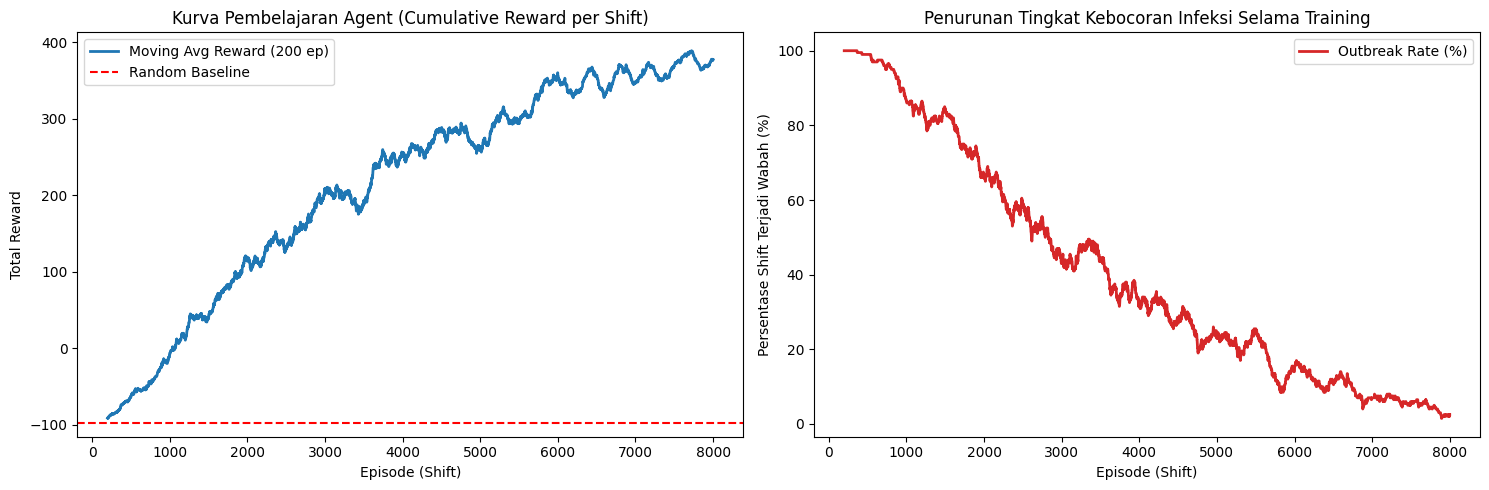

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Moving Average Cumulative Reward
window = 200
moving_avg_reward = pd.Series(reward_history).rolling(window).mean()
axes[0].plot(moving_avg_reward, color="#1f77b4", linewidth=2, label=f"Moving Avg Reward ({window} ep)")
axes[0].axhline(baseline_metrics["Mean Reward"], color="red", linestyle="--", label="Random Baseline")
axes[0].set_title("Kurva Pembelajaran Agent (Cumulative Reward per Shift)")
axes[0].set_xlabel("Episode (Shift)")
axes[0].set_ylabel("Total Reward")
axes[0].legend()

# Plot 2: Moving Average Tingkat Kebocoran Wabah (Outbreak Rate)
moving_avg_outbreak = pd.Series(outbreak_history).rolling(window).mean() * 100
axes[1].plot(moving_avg_outbreak, color="#d62728", linewidth=2, label="Outbreak Rate (%)")
axes[1].set_title("Penurunan Tingkat Kebocoran Infeksi Selama Training")
axes[1].set_xlabel("Episode (Shift)")
axes[1].set_ylabel("Persentase Shift Terjadi Wabah (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
def inspect_learned_policy(agent, env):
    scenarios = [
        ("1. Pengunjung Sehat Total",               (0, 0, 0, 0, 0, 0, 0, 0, 1)),
        ("2. Luka Gigitan + Kulit Hijau",           (2, 0, 2, 1, 2, 0, 0, 0, 1)),
        ("3. Gejala Abu-Abu (Mimisan+Pucat+Gelisah)",(0, 1, 1, 1, 1, 0, 0, 0, 1)),
        ("4. Setelah Cek Vitals: Demam & Pulse Tinggi",(0, 1, 1, 1, 1, 2, 2, 0, 1)),
        ("5. Setelah Tes Darah: NEGATIF (Aman)",    (0, 1, 1, 1, 1, 2, 2, 1, 1)),
        ("6. Setelah Tes Darah: POSITIF (Infeksi)", (0, 1, 1, 1, 1, 2, 2, 2, 1)),
    ]

    print("=== KEBIJAKAN OPTIMAL (POLICY) YANG DIPELAJARI AGENT ===")
    for desc, state in scenarios:
        q_vals = agent.q_table[state]
        best_action = env.action_names[np.argmax(q_vals)]
        print(f"{desc:<45} -> Aksi Terbaik: {best_action:<13} | Q-Values: {np.round(q_vals, 1)}")

inspect_learned_policy(agent, env)

=== KEBIJAKAN OPTIMAL (POLICY) YANG DIPELAJARI AGENT ===
1. Pengunjung Sehat Total                     -> Aksi Terbaik: Approve       | Q-Values: [67.9 51.1 61.2 67.3 59.9]
2. Luka Gigitan + Kulit Hijau                 -> Aksi Terbaik: Deny          | Q-Values: [-85.8  78.8  74.3  26.1  27.4]
3. Gejala Abu-Abu (Mimisan+Pucat+Gelisah)     -> Aksi Terbaik: Check_Vitals  | Q-Values: [ 1.8 59.8 58.6 65.4 62.2]
4. Setelah Cek Vitals: Demam & Pulse Tinggi   -> Aksi Terbaik: Quarantine    | Q-Values: [-19.5  61.5  66.3  63.   48.9]
5. Setelah Tes Darah: NEGATIF (Aman)          -> Aksi Terbaik: Quarantine    | Q-Values: [17.6 16.7 79.3  4.8  0.3]
6. Setelah Tes Darah: POSITIF (Infeksi)       -> Aksi Terbaik: Deny          | Q-Values: [ 0.  87.4 14.3  0.2  0. ]


In [6]:
def detailed_evaluation(env, agent, n_episodes=500):
    decision_matrix = np.zeros((3, 3), dtype=int)
    action_counts = np.zeros(env.n_actions, dtype=int)
    sample_trace = []

    for ep in range(n_episodes):
        state = env.reset()
        done = False
        steps = 0
        visitor_num = 1
        tools_used = []

        while not done and steps < 300:
            action = agent.choose_action(state, training=False)
            action_counts[action] += 1

            v_snapshot = env.current_visitor.copy()
            initial_visual = tuple(v_snapshot["visual"])

            if action == 3:
                tools_used.append("Check_Vitals")
            elif action == 4:
                tools_used.append("Blood_Test")
            else:
                latent = v_snapshot["latent_status"]
                decision_matrix[latent, action] += 1

                if ep == 0 and visitor_num <= 12:
                    luka_map = ["Bersih", "Goresan", "Gigitan"]
                    darah_map = ["Tidak", "Mimisan", "MulutBerdarah"]
                    kulit_map = ["Normal", "Pucat", "Hijau"]
                    mata_map = ["Jernih", "Merah", "Keruh"]
                    perilaku_map = ["Tenang", "Gelisah", "Agresif"]
                    status_map = ["Sehat", "Sakit Biasa", "TERINFEKSI"]

                    gejala_str = (
                        f"Luka:{luka_map[initial_visual[0]]}, "
                        f"Darah:{darah_map[initial_visual[1]]}, "
                        f"Kulit:{kulit_map[initial_visual[2]]}, "
                        f"Mata:{mata_map[initial_visual[3]]}, "
                        f"Sikap:{perilaku_map[initial_visual[4]]}"
                    )
                    sample_trace.append({
                        "Pengunjung": f"#{visitor_num}",
                        "Gejala Visual Awal": gejala_str,
                        "Investigasi Agent": " -> ".join(tools_used) if tools_used else "Langsung Putuskan",
                        "Keputusan Final": env.action_names[action],
                        "Status Asli": status_map[latent],
                        "Hasil": "TEPAT" if (
                            (latent in [0, 1] and action in [0, 2]) or
                            (latent == 2 and action in [1, 2])
                        ) else "SALAH"
                    })

                visitor_num += 1
                tools_used = []

            state, reward, done, _ = env.step(action)
            steps += 1

    return decision_matrix, action_counts, pd.DataFrame(sample_trace)

dec_matrix, act_counts, df_trace = detailed_evaluation(env, agent, n_episodes=500)

print("=== CONTOH LOG KEPUTUSAN AGENT DALAM 1 SHIFT (DEMO VIDEO) ===")
display(df_trace)

=== CONTOH LOG KEPUTUSAN AGENT DALAM 1 SHIFT (DEMO VIDEO) ===


,Pengunjung,Gejala Visual Awal,Investigasi Agent,Keputusan Final,Status Asli,Hasil
0,#1,"Luka:Bersih, Darah:Mimisan, Kulit:Normal, Mata...",Blood_Test,Approve,Sehat,TEPAT
1,#2,"Luka:Gigitan, Darah:MulutBerdarah, Kulit:Hijau...",Blood_Test,Deny,TERINFEKSI,TEPAT
2,#3,"Luka:Goresan, Darah:Tidak, Kulit:Normal, Mata:...",Check_Vitals,Approve,Sehat,TEPAT
3,#4,"Luka:Bersih, Darah:Mimisan, Kulit:Pucat, Mata:...",Blood_Test,Approve,Sakit Biasa,TEPAT
4,#5,"Luka:Goresan, Darah:Tidak, Kulit:Normal, Mata:...",Langsung Putuskan,Quarantine,TERINFEKSI,TEPAT
5,#6,"Luka:Bersih, Darah:Tidak, Kulit:Pucat, Mata:Me...",Check_Vitals,Quarantine,TERINFEKSI,TEPAT
6,#7,"Luka:Bersih, Darah:Tidak, Kulit:Normal, Mata:J...",Langsung Putuskan,Approve,Sehat,TEPAT
7,#8,"Luka:Bersih, Darah:Mimisan, Kulit:Normal, Mata...",Check_Vitals,Deny,TERINFEKSI,TEPAT
8,#9,"Luka:Goresan, Darah:Tidak, Kulit:Pucat, Mata:M...",Blood_Test,Quarantine,TERINFEKSI,TEPAT
9,#10,"Luka:Bersih, Darah:Tidak, Kulit:Normal, Mata:J...",Langsung Putuskan,Approve,Sehat,TEPAT


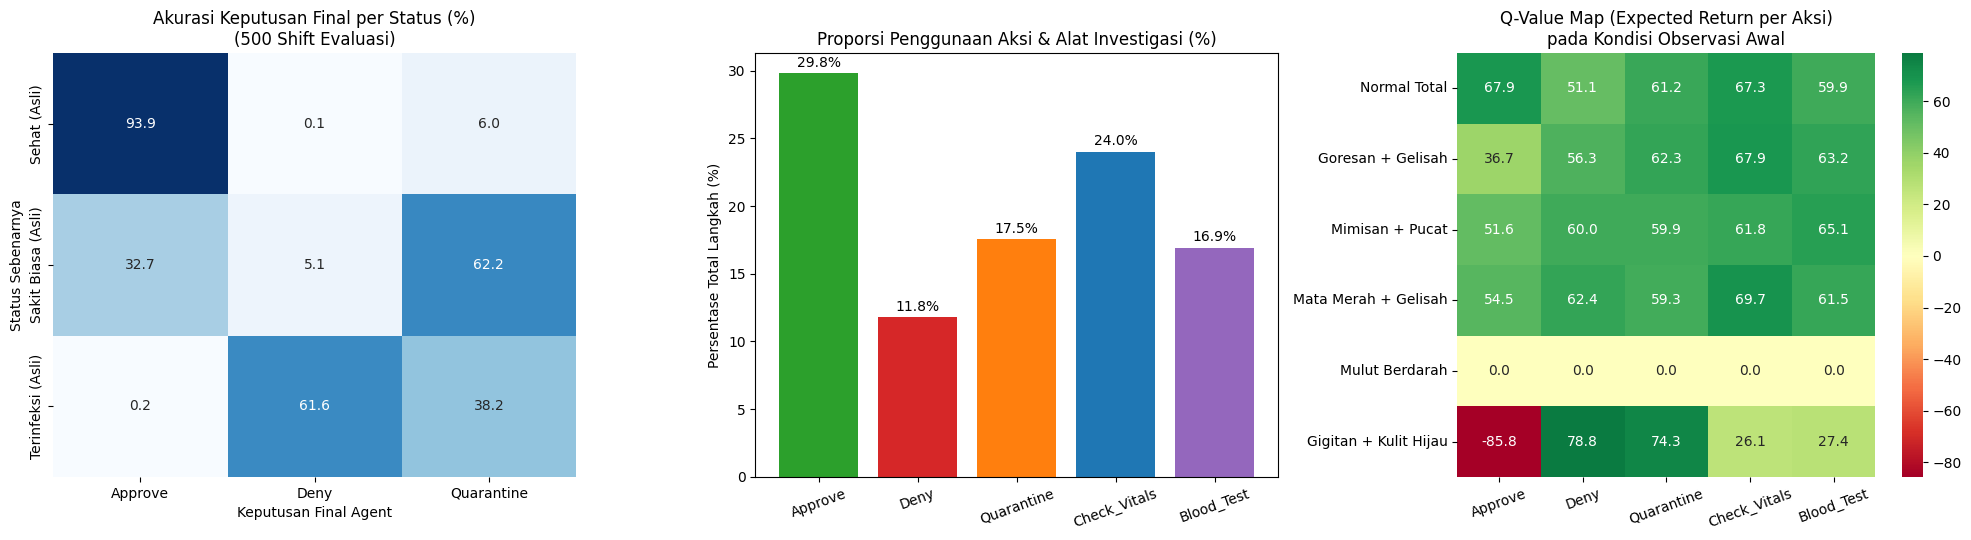

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

dec_pct = dec_matrix / dec_matrix.sum(axis=1, keepdims=True) * 100
sns.heatmap(
    dec_pct, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=["Approve", "Deny", "Quarantine"],
    yticklabels=["Sehat (Asli)", "Sakit Biasa (Asli)", "Terinfeksi (Asli)"]
)
axes[0].set_title("Akurasi Keputusan Final per Status (%)\n(500 Shift Evaluasi)")
axes[0].set_xlabel("Keputusan Final Agent")
axes[0].set_ylabel("Status Sebenarnya")

act_pct = act_counts / act_counts.sum() * 100
colors = ["#2ca02c", "#d62728", "#ff7f0e", "#1f77b4", "#9467bd"]
bars = axes[1].bar(env.action_names, act_pct, color=colors)
axes[1].set_title("Proporsi Penggunaan Aksi & Alat Investigasi (%)")
axes[1].set_ylabel("Persentase Total Langkah (%)")
axes[1].tick_params(axis="x", rotation=20)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 0.5, f"{yval:.1f}%", ha="center", fontsize=10)

sample_states = [
    ("Normal Total", (0, 0, 0, 0, 0, 0, 0, 0, 1)),
    ("Goresan + Gelisah", (1, 0, 0, 0, 1, 0, 0, 0, 1)),
    ("Mimisan + Pucat", (0, 1, 1, 0, 0, 0, 0, 0, 1)),
    ("Mata Merah + Gelisah", (0, 0, 0, 1, 1, 0, 0, 0, 1)),
    ("Mulut Berdarah", (0, 2, 0, 0, 1, 0, 0, 0, 1)),
    ("Gigitan + Kulit Hijau", (2, 0, 2, 1, 2, 0, 0, 0, 1)),
]
q_matrix = np.array([agent.q_table[s] for _, s in sample_states])
sns.heatmap(
    q_matrix, annot=True, fmt=".1f", cmap="RdYlGn", center=0, ax=axes[2],
    xticklabels=env.action_names,
    yticklabels=[label for label, _ in sample_states]
)
axes[2].set_title("Q-Value Map (Expected Return per Aksi)\npada Kondisi Observasi Awal")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()